In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Data analysis and Visualization of last 365 days

In [2]:
df365 = pd.read_csv('cleaned_HandigaunLast365days.csv')
df365

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,2848864,"Dabali, Handigaun",temperature,17.284375,c,2025-10-12 06:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-10-12,06:45:00
1,2848864,"Dabali, Handigaun",temperature,18.441342,c,2025-10-12 07:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-10-12,07:45:00
2,2848864,"Dabali, Handigaun",temperature,21.452698,c,2025-10-12 08:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-10-12,08:45:00
3,2848864,"Dabali, Handigaun",temperature,26.494805,c,2025-10-12 09:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-10-12,09:45:00
4,2848864,"Dabali, Handigaun",temperature,29.211706,c,2025-10-12 10:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-10-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,2848864,"Dabali, Handigaun",temperature,18.038988,c,2025-11-25 17:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-11-25,17:45:00
996,2848864,"Dabali, Handigaun",temperature,17.141518,c,2025-11-25 18:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-11-25,18:45:00
997,2848864,"Dabali, Handigaun",temperature,16.504048,c,2025-11-25 19:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-11-25,19:45:00
998,2848864,"Dabali, Handigaun",temperature,15.684226,c,2025-11-25 20:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-11-25,20:45:00


In [3]:
df365.columns

Index(['location_id', 'location_name', 'parameter', 'value', 'unit',
       'datetimeLocal', 'timezone', 'latitude', 'longitude', 'owner_name',
       'provider', 'date', 'time'],
      dtype='str')

In [4]:
# Convert the date column to a proper datetime value
df365["date"] = pd.to_datetime(df365["date"])

# Group records by date and calculate the daily mean temperature
daily_mean = (
    df365.groupby("date", as_index=False)
      .agg(
          daily_mean_value=("value", "mean"),
          observation_count=("value", "count"),
          location_id=("location_id", "first"),
          location_name=("location_name", "first"),
          parameter=("parameter", "first"),
          unit=("unit", "first"),
          timezone=("timezone", "first"),
          latitude=("latitude", "first"),
          longitude=("longitude", "first"),
          owner_name=("owner_name", "first"),
          provider=("provider", "first"),
      )
)

# Arrange columns in a clear order
daily_mean = daily_mean[
    [
        "date", "location_id", "location_name", "parameter",
        "daily_mean_value", "unit", "observation_count",
        "timezone", "latitude", "longitude", "owner_name", "provider",
    ]
]

In [5]:
daily_mean

,date,location_id,location_name,parameter,daily_mean_value,unit,observation_count,timezone,latitude,longitude,owner_name,provider
0,2025-10-12,2848864,"Dabali, Handigaun",temperature,23.745051,c,18,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
1,2025-10-13,2848864,"Dabali, Handigaun",temperature,21.819272,c,24,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
2,2025-10-14,2848864,"Dabali, Handigaun",temperature,22.301338,c,24,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
3,2025-10-15,2848864,"Dabali, Handigaun",temperature,22.404052,c,24,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
4,2025-10-16,2848864,"Dabali, Handigaun",temperature,22.449942,c,24,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
5,2025-10-17,2848864,"Dabali, Handigaun",temperature,22.971078,c,24,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
6,2025-10-18,2848864,"Dabali, Handigaun",temperature,23.853895,c,24,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
7,2025-10-19,2848864,"Dabali, Handigaun",temperature,23.405935,c,24,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
8,2025-10-20,2848864,"Dabali, Handigaun",temperature,20.147376,c,11,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
9,2025-10-22,2848864,"Dabali, Handigaun",temperature,24.739015,c,17,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient


/tmp/ipykernel_19153/1693882114.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


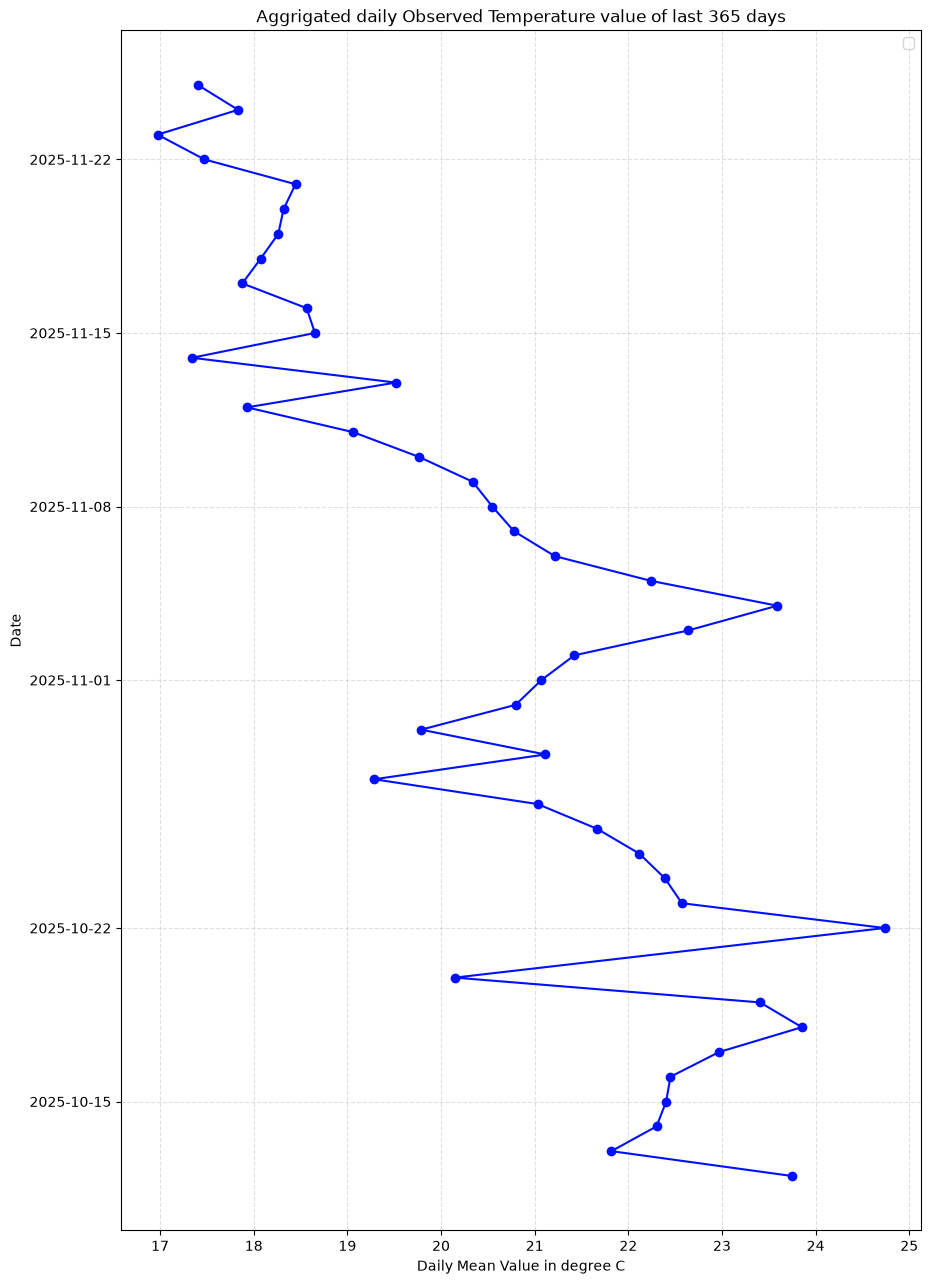

In [6]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_mean['daily_mean_value'], daily_mean['date'], color ='#000fff', marker='o')
plt.xlabel('Daily Mean Value in degree C')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed Temperature value of last 365 days")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 2. Data analysis and Visualization of last 30 days

In [7]:
df30 = pd.read_csv('cleaned_HandigaunLast30days.csv')
df30

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,2848864,"Dabali, Handigaun",temperature,22.7,c,2026-09-12 06:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-09-12,06:45:00
1,2848864,"Dabali, Handigaun",temperature,24.1,c,2026-09-12 07:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-09-12,07:45:00
2,2848864,"Dabali, Handigaun",temperature,27.9,c,2026-09-12 08:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-09-12,08:45:00
3,2848864,"Dabali, Handigaun",temperature,31.2,c,2026-09-12 09:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-09-12,09:45:00
4,2848864,"Dabali, Handigaun",temperature,33.1,c,2026-09-12 10:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-09-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
621,2848864,"Dabali, Handigaun",temperature,19.2,c,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-12,01:45:00
622,2848864,"Dabali, Handigaun",temperature,19.1,c,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-12,02:45:00
623,2848864,"Dabali, Handigaun",temperature,18.7,c,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-12,03:45:00
624,2848864,"Dabali, Handigaun",temperature,18.3,c,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-12,04:45:00


In [8]:
df30.columns

Index(['location_id', 'location_name', 'parameter', 'value', 'unit',
       'datetimeLocal', 'timezone', 'latitude', 'longitude', 'owner_name',
       'provider', 'date', 'time'],
      dtype='str')

In [9]:
# Convert the date column to a proper datetime value
df30["date"] = pd.to_datetime(df30["date"])

# Group records by date and calculate the daily mean temperature
daily_mean = (
    df30.groupby("date", as_index=False)
      .agg(
          daily_mean_value=("value", "mean"),
          observation_count=("value", "count"),
          location_id=("location_id", "first"),
          location_name=("location_name", "first"),
          parameter=("parameter", "first"),
          unit=("unit", "first"),
          timezone=("timezone", "first"),
          latitude=("latitude", "first"),
          longitude=("longitude", "first"),
          owner_name=("owner_name", "first"),
          provider=("provider", "first"),
      )
)

# Arrange columns in a clear order
daily_mean = daily_mean[
    [
        "date", "location_id", "location_name", "parameter",
        "daily_mean_value", "unit", "observation_count",
        "timezone", "latitude", "longitude", "owner_name", "provider",
    ]
]

In [10]:
daily_mean

,date,location_id,location_name,parameter,daily_mean_value,unit,observation_count,timezone,latitude,longitude,owner_name,provider
0,2026-09-12,2848864,"Dabali, Handigaun",temperature,27.922222,c,18,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
1,2026-09-13,2848864,"Dabali, Handigaun",temperature,26.587500,c,24,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
2,2026-09-14,2848864,"Dabali, Handigaun",temperature,25.729167,c,24,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
3,2026-09-15,2848864,"Dabali, Handigaun",temperature,25.737500,c,24,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
4,2026-09-16,2848864,"Dabali, Handigaun",temperature,25.591667,c,24,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
5,2026-09-17,2848864,"Dabali, Handigaun",temperature,23.111111,c,9,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
6,2026-09-20,2848864,"Dabali, Handigaun",temperature,23.216667,c,6,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
7,2026-09-21,2848864,"Dabali, Handigaun",temperature,25.704167,c,24,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
8,2026-09-22,2848864,"Dabali, Handigaun",temperature,25.516667,c,24,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
9,2026-09-23,2848864,"Dabali, Handigaun",temperature,24.379167,c,24,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient


/tmp/ipykernel_19153/3570141088.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


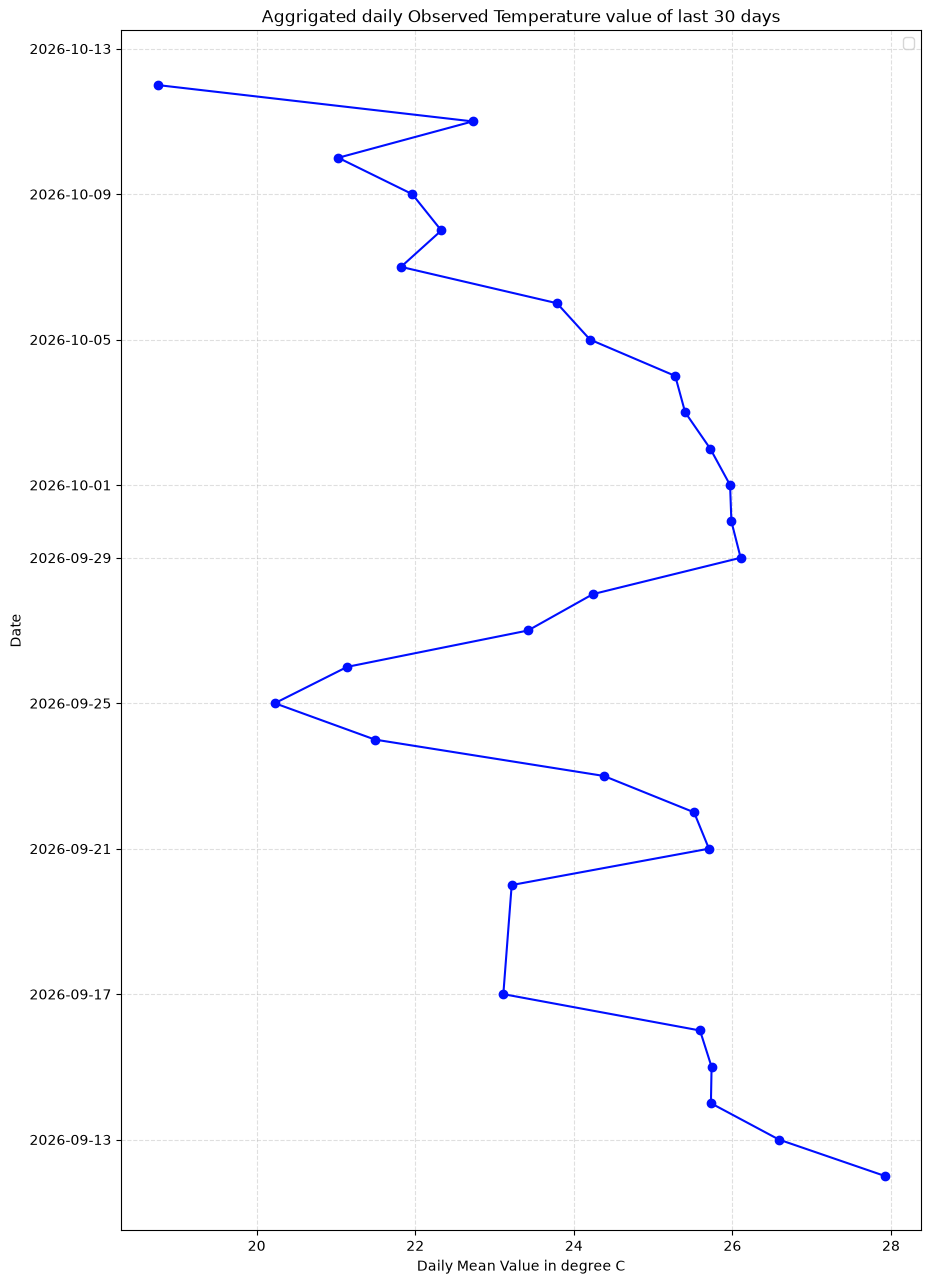

In [11]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_mean['daily_mean_value'], daily_mean['date'], color ='#000fff', marker='o')
plt.xlabel('Daily Mean Value in degree C')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed Temperature value of last 30 days")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 3. Data Analysis and Visualization of last 1 week

In [12]:
df7 = pd.read_csv('cleaned_HandigaunLast7days.csv')
df7

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,2848864,"Dabali, Handigaun",temperature,21.4,c,2026-10-05 06:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-05,06:45:00
1,2848864,"Dabali, Handigaun",temperature,22.6,c,2026-10-05 07:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-05,07:45:00
2,2848864,"Dabali, Handigaun",temperature,25.4,c,2026-10-05 08:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-05,08:45:00
3,2848864,"Dabali, Handigaun",temperature,28.2,c,2026-10-05 09:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-05,09:45:00
4,2848864,"Dabali, Handigaun",temperature,31.6,c,2026-10-05 10:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-05,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,2848864,"Dabali, Handigaun",temperature,19.2,c,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-12,01:45:00
164,2848864,"Dabali, Handigaun",temperature,19.1,c,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-12,02:45:00
165,2848864,"Dabali, Handigaun",temperature,18.7,c,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-12,03:45:00
166,2848864,"Dabali, Handigaun",temperature,18.3,c,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-12,04:45:00


In [13]:
# Convert the date column to a proper datetime value
df7["date"] = pd.to_datetime(df7["date"])

# Group records by date and calculate the daily mean temperature
daily_mean = (
    df7.groupby("date", as_index=False)
      .agg(
          daily_mean_value=("value", "mean"),
          observation_count=("value", "count"),
          location_id=("location_id", "first"),
          location_name=("location_name", "first"),
          parameter=("parameter", "first"),
          unit=("unit", "first"),
          timezone=("timezone", "first"),
          latitude=("latitude", "first"),
          longitude=("longitude", "first"),
          owner_name=("owner_name", "first"),
          provider=("provider", "first"),
      )
)

# Arrange columns in a clear order
daily_mean = daily_mean[
    [
        "date", "location_id", "location_name", "parameter",
        "daily_mean_value", "unit", "observation_count",
        "timezone", "latitude", "longitude", "owner_name", "provider",
    ]
]


In [14]:
daily_mean

,date,location_id,location_name,parameter,daily_mean_value,unit,observation_count,timezone,latitude,longitude,owner_name,provider
0,2026-10-05,2848864,"Dabali, Handigaun",temperature,24.900000,c,18,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
1,2026-10-06,2848864,"Dabali, Handigaun",temperature,23.787500,c,24,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
2,2026-10-07,2848864,"Dabali, Handigaun",temperature,21.820833,c,24,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
3,2026-10-08,2848864,"Dabali, Handigaun",temperature,22.329167,c,24,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
4,2026-10-09,2848864,"Dabali, Handigaun",temperature,21.962500,c,24,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
5,2026-10-10,2848864,"Dabali, Handigaun",temperature,21.029167,c,24,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
6,2026-10-11,2848864,"Dabali, Handigaun",temperature,22.725000,c,24,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient
7,2026-10-12,2848864,"Dabali, Handigaun",temperature,18.750000,c,6,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient


/tmp/ipykernel_19153/3647158116.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


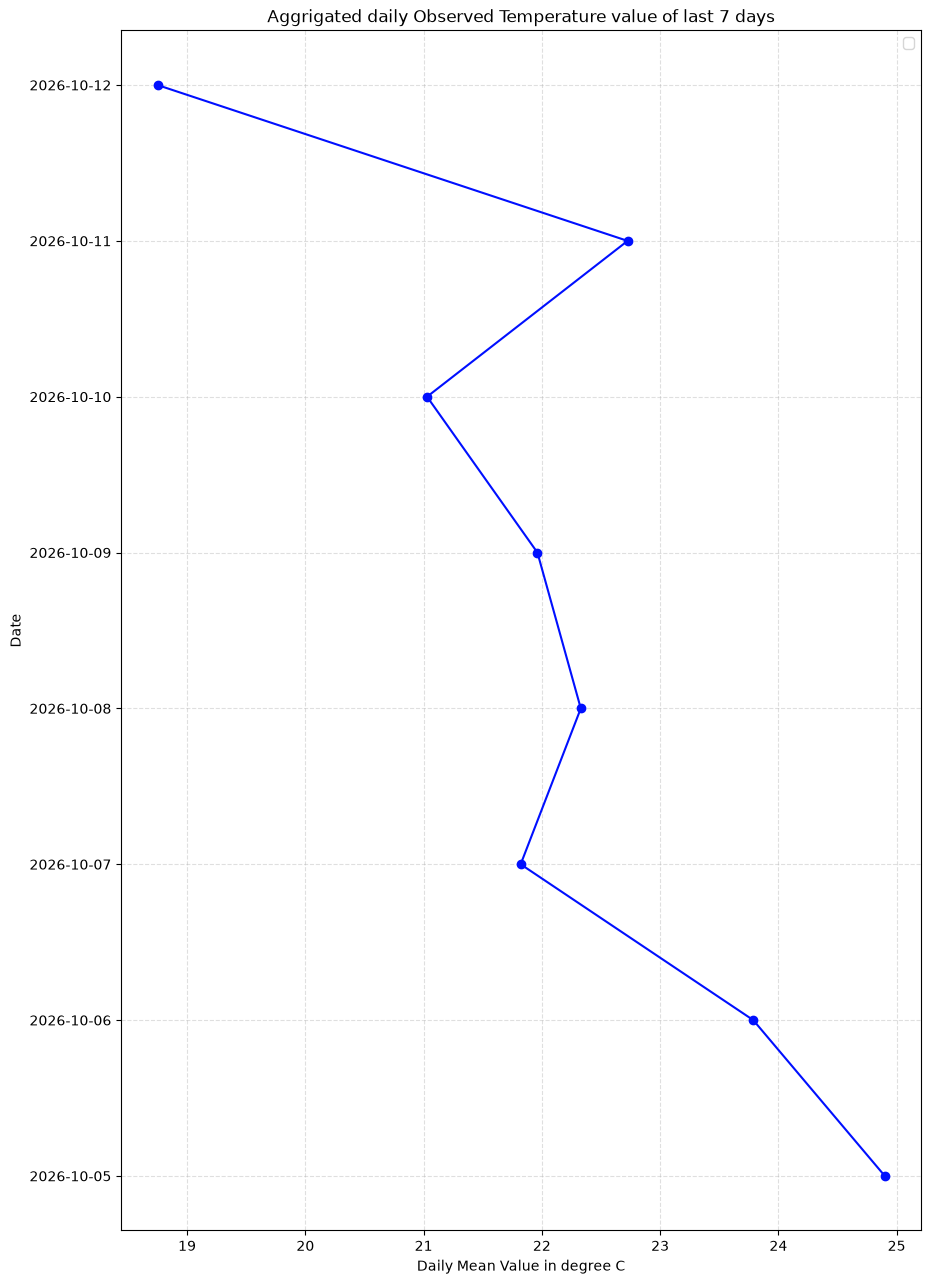

In [15]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_mean['daily_mean_value'], daily_mean['date'], color ='#000fff', marker='o')
plt.xlabel('Daily Mean Value in degree C')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed Temperature value of last 7 days")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 4. Data Analysis and Visualization of last 24 hours

In [16]:
df24 = pd.read_csv('cleaned_HandigaunLast24hours.csv')
df24

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,2848864,"Dabali, Handigaun",temperature,19.5,c,2026-10-11 06:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-11,06:45:00
1,2848864,"Dabali, Handigaun",temperature,20.6,c,2026-10-11 07:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-11,07:45:00
2,2848864,"Dabali, Handigaun",temperature,23.2,c,2026-10-11 08:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-11,08:45:00
3,2848864,"Dabali, Handigaun",temperature,26.8,c,2026-10-11 09:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-11,09:45:00
4,2848864,"Dabali, Handigaun",temperature,29.0,c,2026-10-11 10:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-11,10:45:00
5,2848864,"Dabali, Handigaun",temperature,29.7,c,2026-10-11 11:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-11,11:45:00
6,2848864,"Dabali, Handigaun",temperature,27.8,c,2026-10-11 12:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-11,12:45:00
7,2848864,"Dabali, Handigaun",temperature,27.6,c,2026-10-11 13:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-11,13:45:00
8,2848864,"Dabali, Handigaun",temperature,27.6,c,2026-10-11 14:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-11,14:45:00
9,2848864,"Dabali, Handigaun",temperature,26.9,c,2026-10-11 15:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-11,15:45:00


In [17]:
df24.columns

Index(['location_id', 'location_name', 'parameter', 'value', 'unit',
       'datetimeLocal', 'timezone', 'latitude', 'longitude', 'owner_name',
       'provider', 'date', 'time'],
      dtype='str')

/tmp/ipykernel_19153/318776006.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


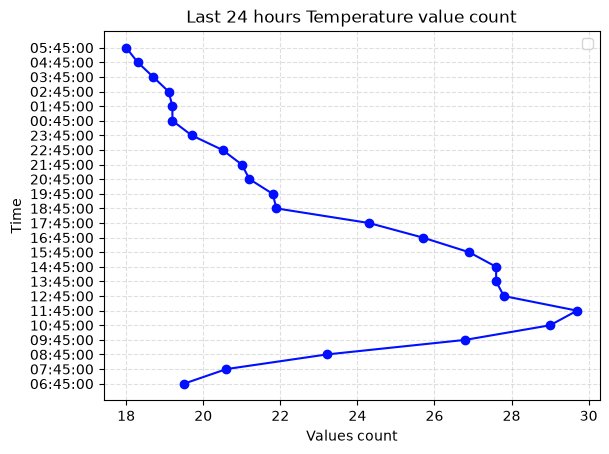

In [18]:
# Line Plot
plt.plot(df24['value'], df24['time'], color='#000fff', marker='o')
plt.xlabel('Values count')
plt.ylabel('Time')
plt.title('Last 24 hours Temperature value count')
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()